# SVD approach to up persistent laplacian with clearing

Want to compute the up Persistent Laplacian Matrix via SVD with and without clearing, then compare to Schur's complement implementation

## Generate a dataset and boundary matrices
We pick only one pair $K \hookrightarrow L$ in the filtration.

In [2]:
import numpy as np
import gudhi
import tadasets

%load_ext autoreload
%autoreload 2

from persistent_laplacian_methods.dense_matrix_methods import *
from persistent_laplacian_methods.dense_boundary_matrix_helpers import *

In [3]:
points = tadasets.torus(
    n=500,
    c=2.0,       
    a=1.0,       
    seed=42,
)

rips = gudhi.RipsComplex(
    points=points,
    max_edge_length=0.9,
)
simplex_tree = rips.create_simplex_tree(
    max_dimension=5,
)

In [4]:
D, levels, cuts = boundary_matrices(simplex_tree)

In [7]:
cuts

array([[   500,      0,      0,      0,      0,      0],
       [   500,      1,      0,      0,      0,      0],
       [   500,      2,      0,      0,      0,      0],
       ...,
       [   500,   4763,  19509,  51343,  97820, 140275],
       [   500,   4764,  19518,  51374,  97875, 140330],
       [   500,   4765,  19523,  51382,  97880, 140331]], shape=(4766, 6))

## Select indices

In [25]:
i, j = 1000, 2000 
q = 4
print("Filtration length: ", len(cuts))
print_boundary_dimensions(D, cuts, i, j)

Filtration length:  4766
matrix             K_1000           K_2000
D_1           (500, 1000)      (500, 2000)
D_2           (1000, 862)     (2000, 3421)
D_3            (862, 463)     (3421, 3576)
D_4            (463, 186)     (3576, 2489)
D_5             (186, 56)     (2489, 1185)


## Schur complement approach using explicit computation of pseudoinverse

In [11]:
prepared = prepare_up_persistent_laplacian(
    D, cuts, q=q, i=i, j=j
)

# Initialize BLAS threadpool
L_q_i_j_schur = compute_schur_D(*prepared)

%timeit compute_schur_D(*prepared)

1.59 s ± 59.4 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [26]:
## profiling schur complement method
from contextlib import contextmanager
from time import perf_counter

B_j, n_q_i, n_q1_i, = prepare_up_persistent_laplacian(
    D, cuts, q=q, i=i, j=j
)

L, profile_info = compute_schur_D_profiling(
    B_j, n_q_i, n_q1_i,
    rcond=1e-12,
)


In [27]:
import pandas as pd
total = profile_info["timings"]["total"]

components = pd.Series(
    {
        name: seconds
        for name, seconds in profile_info["timings"].items()
        if name != "total"
    },
    name="seconds",
)

timing_table = components.to_frame()
timing_table["percent of total"] = 100 * timing_table["seconds"] / total
timing_table = timing_table.sort_values("seconds", ascending=False)

display(
    timing_table.style.format({
        "seconds": "{:.3f}",
        "percent of total": "{:.1f}%",
    })
)

print(f"Total: {total:.3f} seconds")
print("Shapes:", profile_info["shapes"])

,seconds,percent of total
pinv(L_OO),1.008,94.6%
D @ D.T,0.030,2.8%
L_IO @ pinv,0.009,0.8%
B_i @ B_i.T,0.006,0.6%
_blocks,0.005,0.5%
E @ D.T,0.005,0.4%
schur_left @ L_IO.T,0.001,0.1%
E @ E.T,0.001,0.0%
add E term,0.000,0.0%
subtract correction,0.000,0.0%


Total: 1.065 seconds
Shapes: {'B_i': (186, 56), 'E': (186, 1129), 'D': (2303, 1129), 'L_IO': (186, 2303), 'L_OO': (2303, 2303), 'L': (186, 186)}


## Profiling schur: 
- Almost all time is spent computing the pseudoinverse.

## Use SVD to get nullspace and compute Up Persistent Laplacian directly

In [15]:
prepared = prepare_up_persistent_laplacian(
    D, cuts, q=q, i=i, j=j
)

# Initialize BLAS threadpool
L_q_i_j_naive = compute_null_space_D(*prepared)

%timeit compute_null_space_D(*prepared)

3.75 s ± 89.7 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [16]:
## Check
np.allclose(L_q_i_j_schur, L_q_i_j_naive, rtol=1e-12, atol=1e-12)

True

## Profiling SVD

In [28]:

L_null, null_profile = compute_null_space_D_profiling(
    B_j,
    n_q_i,
    n_q1_i,
    rcond=1e-6,
)

In [29]:
import pandas as pd


def display_profile(profile_info):
    total = profile_info["timings"]["total"]

    components = pd.Series(
        {
            name: seconds
            for name, seconds in profile_info["timings"].items()
            if name != "total"
        },
        name="seconds",
    )

    table = components.to_frame()
    table["percent of total"] = 100 * table["seconds"] / total
    table = table.sort_values("seconds", ascending=False)

    display(
        table.style.format({
            "seconds": "{:.3f}",
            "percent of total": "{:.1f}%",
        })
    )

    print(f"Total: {total:.3f} seconds")
    print(f"Exit reason: {profile_info['exit_reason']}")
    print("Shapes:", profile_info["shapes"])

display_profile(null_profile)

,seconds,percent of total
null_space(D),0.452,97.3%
_blocks,0.010,2.1%
E @ Z,0.002,0.4%
B_i @ B_i.T,0.001,0.2%
EZ @ EZ.T,0.000,0.0%
add null-space term,0.000,0.0%


Total: 0.464 seconds
Exit reason: full null-space computation
Shapes: {'B_i': (186, 56), 'E': (186, 1129), 'D': (2303, 1129), 'Z': (1129, 306), 'EZ': (186, 306), 'L': (186, 186)}


## Reduced SVD trick

In [ ]:
prepared = prepare_up_persistent_laplacian(
    D, cuts, q=q, i=i, j=j
)

# Initialize BLAS threadpool
L_q_i_j_reduced = compute_reduced_svd_D(*prepared)

%timeit compute_reduced_svd_D(*prepared)

In [ ]:
## Check
np.allclose(L_q_i_j_schur, L_q_i_j_reduced, rtol=1e-12, atol=1e-12)

True

## Compute for all dimensions

In [ ]:
from functools import partial
from pathlib import Path
import timeit

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from persistent_laplacian_methods import *


REPEATS = 5
NUMBER = 1

rcond_svd = 1e-6
rcond_schur = rcond_svd**2

q_values = [p - 1 for p in sorted(D)]

def arguments_for(q):
    n_q_i = int(cuts[i][q])
    n_q1_i = int(cuts[i][q + 1])
    n_q_j = int(cuts[j][q])
    n_q1_j = int(cuts[j][q + 1])

    # Up-Laplacian in dimension q uses boundary matrix D_{q+1}
    B_j = D[q + 1][:n_q_j, :n_q1_j]

    B_j = np.ascontiguousarray(B_j, dtype=np.float64)

    return B_j, n_q_i, n_q1_i
rows = []


def record_timings(method, q, run, D_shape, B_j_shape, clearing_h=np.nan):
    samples = timeit.repeat(
        run,
        repeat=REPEATS,
        number=NUMBER,
    )

    for repeat, elapsed in enumerate(samples, start=1):
        rows.append({
            "q": q,
            "method": method,
            "repeat": repeat,
            "seconds": elapsed / NUMBER,
            "B_j_rows": B_j_shape[0],
            "B_j_cols": B_j_shape[1],
            "D_rows": D_shape[0],
            "D_cols": D_shape[1],
            "clearing_h": clearing_h,
        })

# Independent methods
for q in q_values:
    B_j, n_q_i, n_q1_i = arguments_for(q)
    B_j_shape = B_j.shape
    D_shape = B_j[n_q_i:, n_q1_i:].shape

    methods = {
        "Schur": partial(
            compute_schur_D,
            B_j,
            n_q_i,
            n_q1_i,
            rcond=rcond_schur,
        ),
        "Null-space SVD": partial(
            compute_null_space_D,
            B_j,
            n_q_i,
            n_q1_i,
            rcond=rcond_svd,
        ),
        "Reduced SVD": partial(
            compute_reduced_svd_D,
            B_j,
            n_q_i,
            n_q1_i,
            rcond=rcond_svd,
        ),
        "Least squares Schur": partial(
            compute_schur_D_lstsq,
            B_j,
            n_q_i,
            n_q1_i,
            rcond=rcond_svd
        )
    }

    for method, run in methods.items():
        print(f"Timing {method}, q={q}")
        record_timings(method, q, run, D_shape, B_j_shape)


# Clearing SVD: process dimensions from high to low
higher_output = None

for q in reversed(q_values):
    B_j, n_q_i, n_q1_i = arguments_for(q)
    B_j_shape = B_j.shape
    D_shape = B_j[n_q_i:, n_q1_i:].shape

    # h = rank(D_{q+2}), supplied by the computation above.
    # At the highest dimension, no directions have yet been cleared.
    clearing_h = 0 if higher_output is None else higher_output[1]

    run = partial(
        compute_null_space_clearing_D,
        B_j,
        n_q_i,
        n_q1_i,
        higher_output=higher_output,
        rcond=rcond_svd,
    )

    print(f"Timing Clearing SVD, q={q}, h={clearing_h}")
    record_timings(
        "Clearing SVD",
        q,
        run,
        B_j_shape,
        D_shape,
        clearing_h=clearing_h,
    )

    # Obtain the rank information to use at dimension q - 1.
    L_clearing, higher_output = run()

    L_schur_lstsq = compute_schur_D_lstsq(
        B_j,
        n_q_i,
        n_q1_i,
        rcond=rcond_svd,
    )

    assert np.allclose(
        L_clearing,
        L_schur_lstsq,
        rtol=1e-8,
        atol=1e-10,
    ), f"Clearing disagrees with Schur least squares at q={q}"


print("Clearing agrees with Schur least squares in every dimension.")


timings = pd.DataFrame(rows)

summary = (
    timings
    .groupby(
        ["q", "method", "B_j_rows", "B_j_cols", "D_rows", "D_cols"],
        as_index=False,
    )
    .agg(
        clearing_h=("clearing_h", "first"),
        median_seconds=("seconds", "median"),
        min_seconds=("seconds", "min"),
        max_seconds=("seconds", "max"),
    )
)

summary["clearing_h"] = summary["clearing_h"].astype("Int64")

display(summary)

Timing Schur, q=0
Timing Null-space SVD, q=0
Timing Reduced SVD, q=0
Timing Least squares Schur, q=0
Timing Schur, q=1
Timing Null-space SVD, q=1
Timing Reduced SVD, q=1
Timing Least squares Schur, q=1
Timing Schur, q=2
Timing Null-space SVD, q=2
Timing Reduced SVD, q=2
Timing Least squares Schur, q=2
Timing Schur, q=3
Timing Null-space SVD, q=3
Timing Reduced SVD, q=3
Timing Least squares Schur, q=3
Timing Schur, q=4
Timing Null-space SVD, q=4
Timing Reduced SVD, q=4
Timing Least squares Schur, q=4
Timing Clearing SVD, q=4, h=0
Timing Clearing SVD, q=3, h=823
Timing Clearing SVD, q=2, h=1480
Timing Clearing SVD, q=1, h=1633
Timing Clearing SVD, q=0, h=914
Clearing agrees with Schur least squares in every dimension.


,q,method,B_j_rows,B_j_cols,D_rows,D_cols,clearing_h,median_seconds,min_seconds,max_seconds
0,0,Clearing SVD,500,2000,0,1000,914,0.006470,0.006272,0.008334
1,0,Least squares Schur,0,1000,500,2000,<NA>,0.002379,0.002261,0.002795
2,0,Null-space SVD,0,1000,500,2000,<NA>,0.002715,0.002529,0.004088
3,0,Reduced SVD,0,1000,500,2000,<NA>,0.002399,0.002265,0.002944
4,0,Schur,0,1000,500,2000,<NA>,0.003299,0.002877,0.009751
5,1,Clearing SVD,2000,3421,1000,2559,1633,0.172053,0.168595,0.183592
6,1,Least squares Schur,1000,2559,2000,3421,<NA>,0.289750,0.283625,0.368151
7,1,Null-space SVD,1000,2559,2000,3421,<NA>,0.461851,0.459313,0.489264
8,1,Reduced SVD,1000,2559,2000,3421,<NA>,0.233474,0.232069,0.250261
9,1,Schur,1000,2559,2000,3421,<NA>,0.131559,0.129767,0.167038


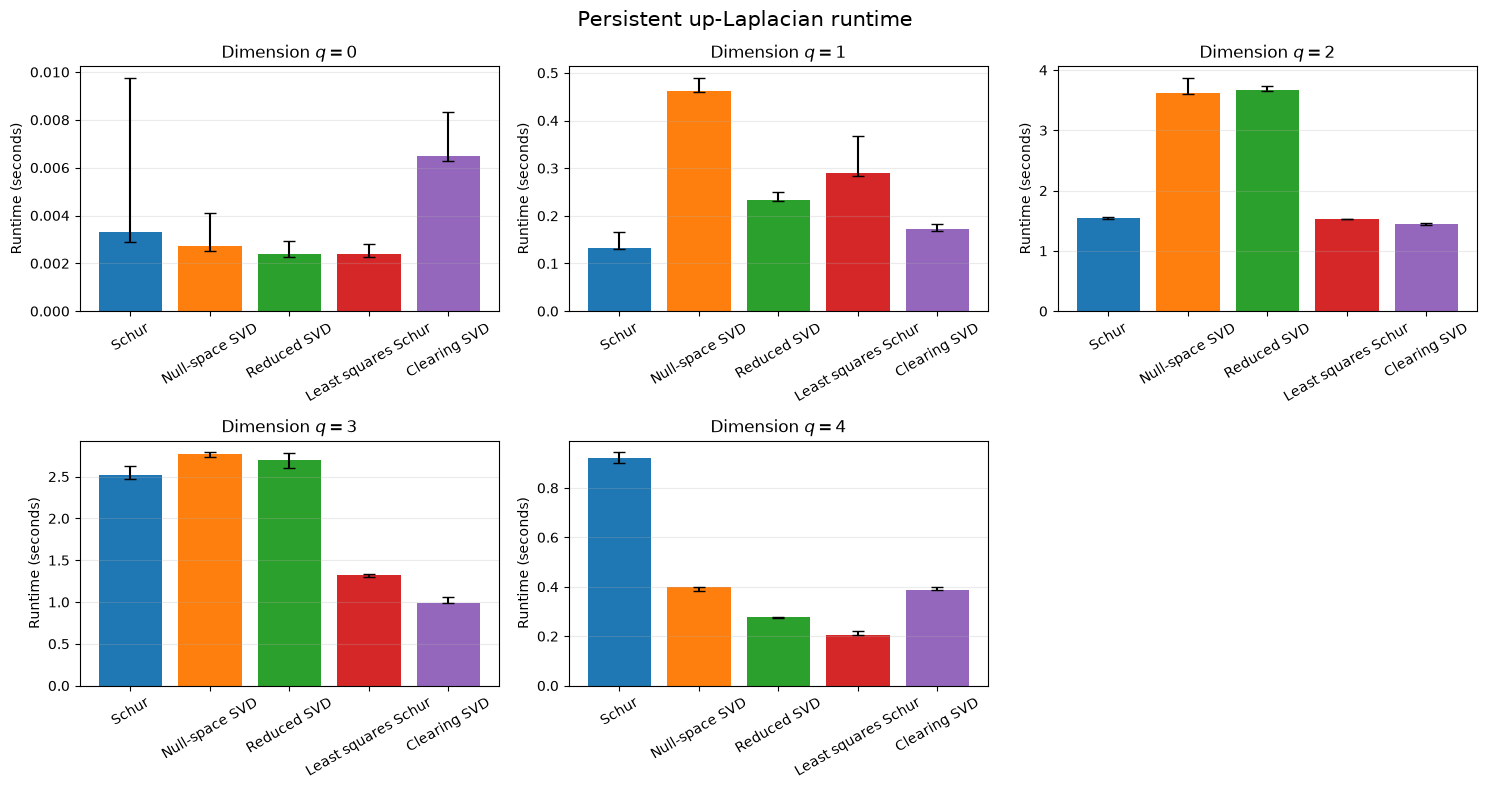

In [6]:
import math
import matplotlib.pyplot as plt
import numpy as np

q_values = np.sort(summary["q"].unique())
method_order = [
    "Schur",
    "Null-space SVD",
    "Reduced SVD",
    "Least squares Schur",
    "Clearing SVD",
]

ncols = 3
nrows = math.ceil(len(q_values) / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(5 * ncols, 4 * nrows),
)
axes = np.atleast_1d(axes).ravel()

colors = dict(zip(method_order, plt.cm.tab10.colors))

for ax, q in zip(axes, q_values):
    data = summary[summary["q"] == q].copy()
    data["method"] = pd.Categorical(
        data["method"],
        categories=method_order,
        ordered=True,
    )
    data = data.sort_values("method")

    median = data["median_seconds"].to_numpy()
    lower = median - data["min_seconds"].to_numpy()
    upper = data["max_seconds"].to_numpy() - median

    ax.bar(
        data["method"].astype(str),
        median,
        yerr=np.vstack([lower, upper]),
        color=[colors[m] for m in data["method"]],
        capsize=4,
    )

    ax.set_title(f"Dimension $q={q}$")
    ax.set_ylabel("Runtime (seconds)")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.25)

# Hide the unused sixth panel
for ax in axes[len(q_values):]:
    ax.set_visible(False)

fig.suptitle("Persistent up-Laplacian runtime", fontsize=15)
fig.tight_layout()
plt.show()